In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
import numpy as np
from pandas.plotting import lag_plot
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


In [3]:
series=pd.read_csv(r"C:\Users\Pc\Documents\pfa_stage_project\data\processed\model_data\time_series.csv",header=0,index_col=0,parse_dates=True).squeeze()
series.head()

Date
1967-01-01    25.5
1967-02-01    25.5
1967-03-01    25.5
1967-04-01    25.5
1967-05-01    25.5
Name: KCL, dtype: float64

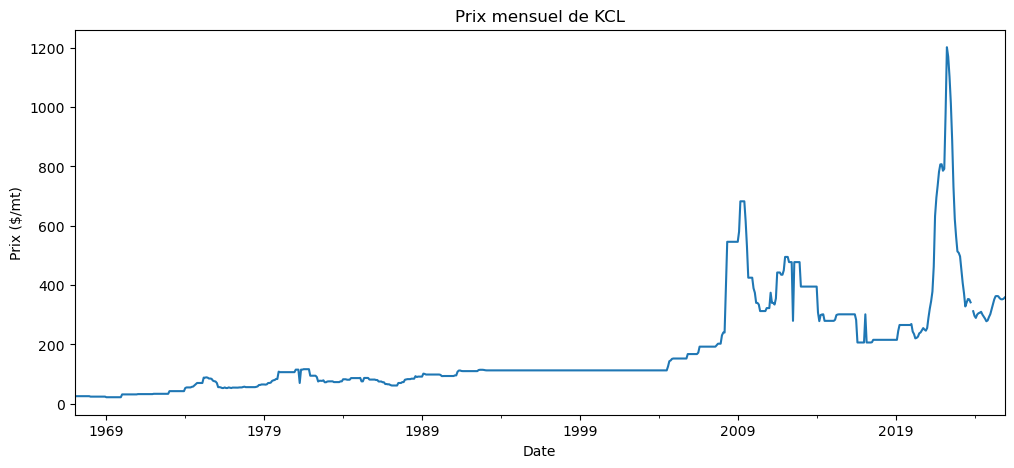

In [ ]:
series = series.asfreq('MS')
series.plot(figsize=(12,5))
plt.title("Prix mensuel de KCL")
plt.xlabel("Date")
plt.ylabel("Prix ($/mt)")
plt.show()

In [7]:
print(type(series))

<class 'pandas.core.series.Series'>


In [9]:
# #summary statistics
print("Summary statistics:\n")
print(series.describe())

Summary statistics:

count     707.000000
mean      177.519823
std       168.897409
min        22.000000
25%        75.500000
50%       112.500000
75%       240.190000
max      1202.000000
Name: KCL, dtype: float64


In [12]:
series.isna().sum()

np.int64(1)

In [15]:
# Remplacer les infinis par NaN (si besoin)
series = series.replace([np.inf, -np.inf], np.nan)

In [16]:
clean_series = series.dropna()

In [18]:
#test de stationnarité
result=adfuller(clean_series)
print("ADF Statistic:",result[0])
print("p-value:,",result[1])
# interpretation
if result[1] < 0.05:
    print("La série est stationnaire")
else:
    print("La série n'est pas stationnaire")

ADF Statistic: -2.07864399839044
p-value:, 0.25318820316219454
La série n'est pas stationnaire


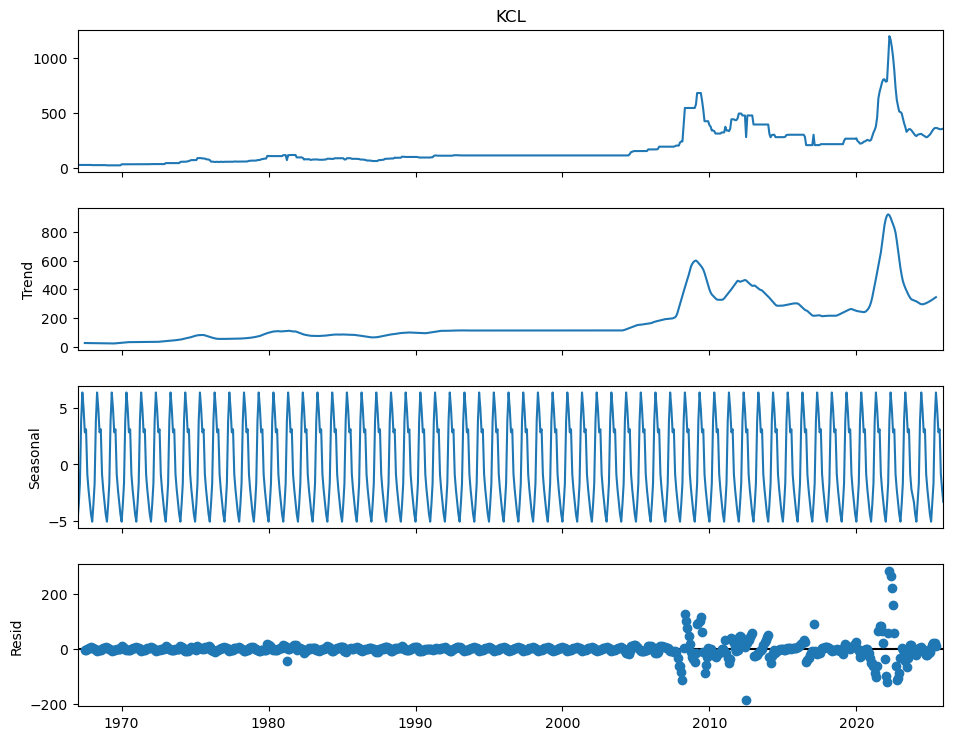

In [19]:
# décomposition de la série
#additive
decomposition = seasonal_decompose(clean_series, model='additive',period=12)
# affichage des composantes
fig = decomposition.plot()
fig.set_size_inches(10,8)
plt.show()

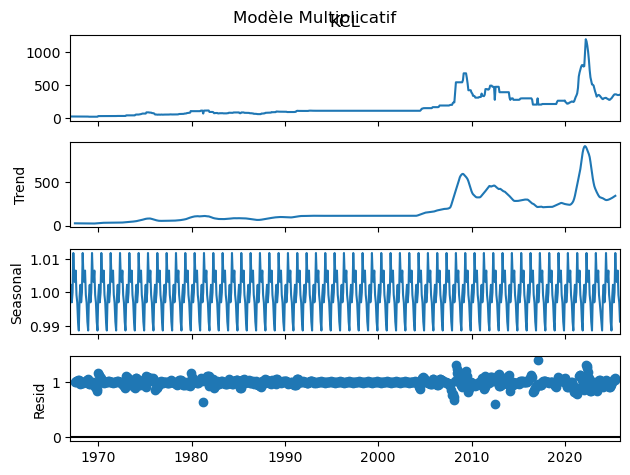

In [20]:
#multiplicative
decomposition_multiplicative = seasonal_decompose(clean_series,model='multiplicative',period=12)
decomposition_multiplicative.plot()
plt.suptitle("Modèle Multiplicatif")
plt.show()

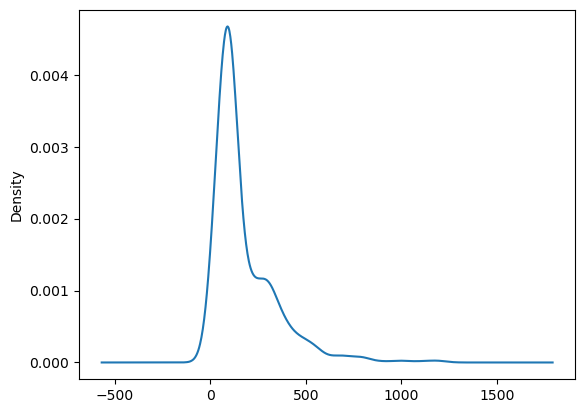

In [21]:
clean_series.plot(kind='kde')
plt.show()

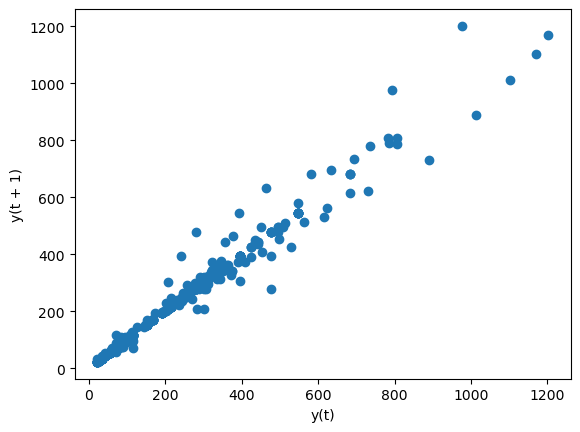

In [24]:
lag_plot(clean_series)
plt.show()

<Figure size 1200x500 with 0 Axes>

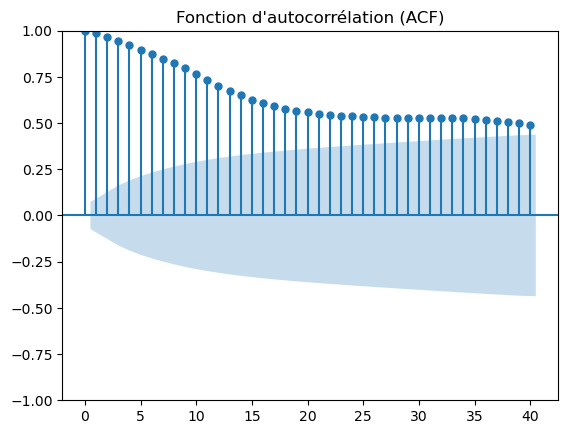

In [29]:
# ACF
plt.figure(figsize=(12,5))
plot_acf(clean_series, lags=40)
plt.title("Fonction d'autocorrélation (ACF)")
plt.show()

<Figure size 1200x500 with 0 Axes>

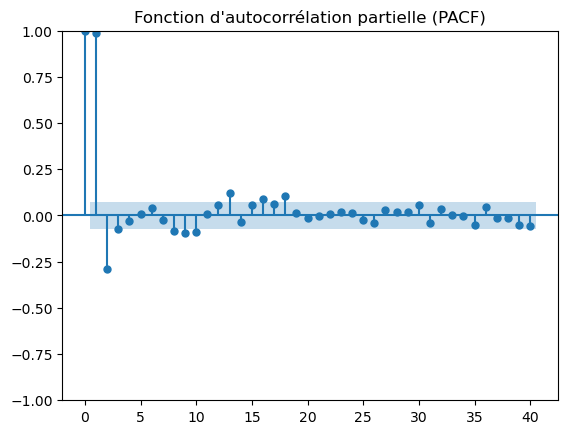

In [30]:
# PACF
plt.figure(figsize=(12,5))
plot_pacf(clean_series, lags=40, method="ywm")
plt.title("Fonction d'autocorrélation partielle (PACF)")
plt.show()

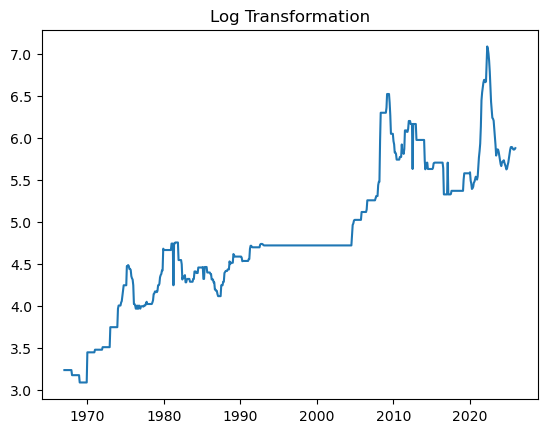

In [31]:
data_log=np.log(clean_series)
plt.plot(data_log)

plt.title("Log Transformation")

plt.show()

In [32]:
#test de stationnarité
result=adfuller(data_log)
print("ADF Statistic:",result[0])
print("p-value:,",result[1])
# interpretation
if result[1] < 0.05:
    print("La série est stationnaire")
else:
    print("La série n'est pas stationnaire")

ADF Statistic: -1.709500724246659
p-value:, 0.4262241856829314
La série n'est pas stationnaire


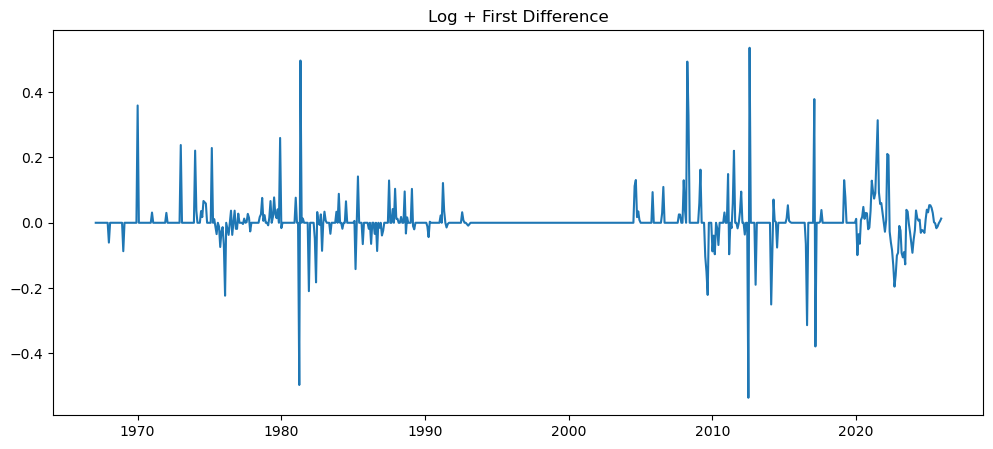

In [ ]:
#differenciation d'ordre 1
data_log_diff=data_log.diff().dropna()
plt.figure(figsize=(12,5))
plt.plot(data_log_diff)
plt.title("Log + First Difference")
plt.show()

In [35]:
#test de stationnarité
result=adfuller(data_log_diff)
print("ADF Statistic:",result[0])
print("p-value:",result[1])
# interpretation
if result[1] < 0.05:
    print("La série est stationnaire")
else:
    print("La série n'est pas stationnaire")

ADF Statistic: -8.209543985247155
p-value: 6.877617316714171e-13
La série est stationnaire
